# Итоговый проект: гибридная рекомендательная система книг

Это продолжение первого ДЗ на Goodbooks-10k. В первой работе уже были Popularity, TF-IDF, Item-Based CF и SVD. Здесь я хочу объединить их, добавить признаки пользователей и книг, а затем проверить нейросетевой ранжировщик.

Проверю три идеи:

1. Общий пул кандидатов и взвешивание моделей могут улучшить рекомендации по сравнению с отдельными подходами.
2. Статистики пользователей, книг и тематические признаки могут помочь MLP лучше расставить кандидатов.
3. Можно сделать выдачу разнообразнее и при этом не слишком потерять в релевантности.

Код вынесен в `recommender.py`, чтобы один и тот же процесс запускался из ноутбука и командной строки.

In [1]:
from pathlib import Path
import inspect
import json
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, Image, Code

from recommender import Config, run_experiment, fit_rankers, FEATURE_NAMES
from reporting import make_figures, write_documents, conclusions

ROOT = Path.cwd()
assert (ROOT / "data" / "ratings.csv").exists(), "Запустите ноутбук из rec_system_2"
cfg = Config(**json.loads((ROOT / "config.json").read_text()))
pd.set_option("display.max_columns", 20)
display(pd.Series(vars(cfg), name="Значение").to_frame())

,Значение
seed,42.00
cold_users,300.00
cold_books,100.00
rank_train_users,3500.00
valid_users,600.00
test_users,2500.00
cold_eval_users,1000.00
per_source,80.00
neighbors,50.00
min_ratings,30.00


## 1. Данные и признаки

Использую копию четырёх CSV из первой работы. Повторяющиеся пары пользователь–книга убираю, оставляя последнюю строку. Это не обязательно самая поздняя оценка: времени в файле нет. Внутренние ID преобразуются в последовательные индексы, а в выдаче остаются исходные ID каталога.

Длинный хвост в этой локальной версии сглажен: у книги не больше примерно 100 оценок. Поэтому популярность считаю по обучению, а не беру готовый счётчик из Goodreads. Метаданные — название, автор и теги — считаю доступными и для новых книг.

Соберу несколько групп признаков:

- пользователь: средняя оценка, логарифм числа оценок, доля положительных, разброс оценок и разнообразие тем в истории;
- книга: число оценок, среднее, стандартное отклонение, энтропия распределения оценок и доля положительных;
- пара пользователь–книга: контентная близость, совпадение тем, разность средних, поддержка соседями CF;
- 16 тематических категорий из тегов: fantasy, romance, mystery и другие.

Активность здесь означает объём истории, а не число действий в день. Все статистики оценок считаются только по текущему обучению.

## 2. Разбиение и порядок обучения

Сначала отложу 300 пользователей целиком и 100 книг со всеми оценками остальных пользователей. Так получится настоящая проверка отсутствия истории. Пересечения относятся к тесту новых пользователей.

Оставшиеся оценки разделю внутри пользователей на train, validation и test, как в ДЗ1. Пользователей с менее чем пятью оценками на текущем шаге целиком оставляю в обучении.

Из train дополнительно выделю часть `rank_train`. Базовые модели обучаются на `core`, а признаки кандидатов для обучения MLP считаются без оценок из `rank_train`. Положительные примеры MLP — книги с оценкой ≥4 в `rank_train`, которые уже попали в пул. На каждый положительный пример беру до десяти кандидатов без положительной отложенной оценки. Это условные негативы, а не доказательство неинтересности.

На validation выбираю эпоху MLP, веса и разнообразие. После этого переобучаю базовые модели на train + validation, но не заменяю обучающие признаки MLP прогнозами на уже известных ему целях. MLP остаётся обученным на внутренних отложенных примерах. У финальных признаков будет несколько другое распределение из-за большей истории — это ограничение схемы.

## 3. Базовые модели и кандидаты

Из ДЗ1 перенесены Popularity со средним рейтингом и порогом 30 оценок, TF-IDF, Item-CF с 50 соседями и `surprise.SVD`. Параметры SVD фиксирую по первой работе: 64 фактора, 30 эпох, регуляризация 0.1.

Для CF также сделаю вариант `CF Retrieval`: по той же матрице соседств сложу сходства с положительно оценёнными книгами с весами 1 для оценки 4 и 2 для оценки 5. Это отдельный способ ранжирования, его результат не называю прогнозом рейтинга.

Из каждого источника возьму top-80, объединю книги без повторов и удалю уже оценённые. Четыре модели из ДЗ1 сохраняют свои top-10 в таком пуле. Ранжировщик не получает релевантные книги извне пула.

## 4. Нейросетевой ранжировщик и гибрид

Выбрал MLP с архитектурой **34 → 64 → 32 → 1**: ReLU в скрытых слоях и sigmoid на выходе. Реализация — `MLPClassifier` из scikit-learn, оптимизация Adam, функция потерь binary cross-entropy. StandardScaler обучается только по строкам обучающей части MLP. Вероятность относится к искусственно собранным кандидатам, её нельзя трактовать как настоящую вероятность того, что книга понравится.

Для проверки признаков обучу контрольную сеть **5 → 64 → 32 → 1**, используя только оценки базовых моделей. У неё те же примеры, оптимизатор и правило выбора эпохи. Эпоху выбираю по validation nDCG@5, максимум — 12, остановка после трёх эпох без улучшения.

Классический гибрид — взвешенная сумма нормированных значений пяти источников. Веса подбираю по validation nDCG@5 из небольшой сетки. При 1–4 оценках даю больше веса контенту; без истории использую Popularity. Для новых книг отдельно включается контентная ветка.

Затем смешаю классический гибрид с MLP, проверив веса нейросети 0, 0.25, 0.5, 0.75 и 1.

Для разнообразия применю MMR к лучшим 100 кандидатам. На каждом шаге беру книгу с большим значением λ × релевантность − (1 − λ) × похожесть на уже выбранные. Похожесть — максимум тематической близости и штрафа 0.8 за того же автора. Проверю λ = 0.8, 0.9 и 1. Выберу более разнообразный вариант, если на validation сохраняется хотя бы 98% исходного nDCG@5.

In [2]:
# Здесь обучение, подбор параметров и итоговая оценка выполняются с нуля.
bundle, tables, report = run_experiment(ROOT, cfg)
display(pd.Series(report["splits"], name="Оценки").to_frame())
print("Строки MLP:", report["sampling"])

1/7: данные и разбиение


2/7: базовые модели на внутреннем train


3/7: MLP с расширенными признаками и контрольный вариант


4/7: подбор весов и разнообразия на validation


5/7: финальные базовые модели и тест


6/7: новые пользователи и книги


7/7: проверки и сохранение результатов


,Оценки
core,551599
rank_train,106744
validation,134308
test,170108
cold_users,6925
cold_books,9794


Строки MLP: {'users_with_hits': 2363, 'users_without_hits': 1137, 'examples': 53724, 'positives': 4884, 'negatives': 48840, 'nn_base_epoch': 7, 'nn_base_validation_nDCG5': 0.12056843847643028, 'nn_epoch': 6, 'nn_validation_nDCG5': 0.11654986556906766}


In [3]:
print("Архитектура полной сети:", [matrix.shape for matrix in bundle.rankers["nn"][1].coefs_])
print("Архитектура контрольной сети:", [matrix.shape for matrix in bundle.rankers["nn_base"][1].coefs_])
display(tables["feature_examples"].iloc[:5])
display(tables["feature_statistics"][["mean", "std", "min", "max"]])

Архитектура полной сети: [(34, 64), (64, 32), (32, 1)]
Архитектура контрольной сети: [(5, 64), (64, 32), (32, 1)]


,pop_mean,content_cosine,cf_prediction,svd_prediction,cf_positive,user_mean,user_log_count,user_positive_fraction,user_std,user_topic_entropy,...,genre_classics,genre_thriller,genre_horror,genre_non-fiction,genre_biography,genre_history,genre_poetry,genre_children,genre_comics,genre_philosophy
0,4.541667,0.126214,4.215278,4.707013,0.0,3.888889,2.302585,0.777778,0.87489,1.986573,...,0.592251,0.0,0.0,0.000000,0.0,0.339958,0.0,0.0,0.0,0.000000
1,4.339622,0.209253,4.114256,4.445710,0.0,3.888889,2.302585,0.777778,0.87489,1.986573,...,0.463805,0.0,0.0,0.000000,0.0,0.460151,0.0,0.0,0.0,0.000000
2,3.706897,0.361896,3.797893,3.807343,0.0,3.888889,2.302585,0.777778,0.87489,1.986573,...,0.475240,0.0,0.0,0.280096,0.0,0.000000,0.0,0.0,0.0,0.448918
3,4.440000,0.055566,4.164444,4.764586,0.0,3.888889,2.302585,0.777778,0.87489,1.986573,...,0.386614,0.0,0.0,0.000000,0.0,0.000000,0.0,0.0,0.0,0.000000
4,4.035714,0.220368,3.962301,4.276712,0.0,3.888889,2.302585,0.777778,0.87489,1.986573,...,0.489081,0.0,0.0,0.000000,0.0,0.000000,0.0,0.0,0.0,0.000000


,mean,std,min,max
pop_mean,4.159149,0.427192,1.984848,4.829787
content_cosine,0.179470,0.299506,0.000000,4.829787
cf_prediction,4.297423,0.533741,1.000000,5.000000
svd_prediction,4.178442,0.522789,1.000000,5.000000
cf_positive,0.134007,0.376813,0.000000,17.923136
user_mean,3.942302,0.535457,1.421053,5.000000
user_log_count,2.703546,0.687085,1.609438,4.644391
user_positive_fraction,0.696535,0.227403,0.000000,1.000000
user_std,0.743721,0.291225,0.000000,2.000000
user_topic_entropy,1.856980,0.457489,-0.000000,2.638873


Ниже оставлю функцию обучения MLP, чтобы было видно, какие примеры поступают в сеть и как выбирается эпоха. Основной код подготовки кандидатов находится рядом в `recommender.py`.

In [4]:
display(Code(inspect.getsource(fit_rankers), language="python"))
display(tables["hybrid_weights_validation"])
display(tables["neural_weight_validation"])
display(tables["diversity_validation"].round(4))
print("Выбранные настройки:", report["selected"])

def fit_rankers(train_cache, valid_cache, cfg):
    X, y, sampling = training_pairs(train_cache, cfg)
    val_X = np.concatenate([r['X'] for r in valid_cache])
    rankers, history = {}, []
    for key, columns in [('nn_base', np.arange(5)), ('nn', np.arange(len(FEATURE_NAMES)))]:
        scaler = StandardScaler().fit(X[:, columns])
        xt, xv = scaler.transform(X[:, columns]), scaler.transform(val_X[:, columns])
        model = MLPClassifier(hidden_layer_sizes=(64, 32), activation='relu', solver='adam',
                              batch_size=512, learning_rate_init=.001, alpha=.01,
                              early_stopping=False, random_state=cfg.seed)
        best, best_value, best_epoch, stale = None, -np.inf, 0, 0
        for epoch in range(1, cfg.mlp_epochs + 1):
            model.partial_fit(xt, y, classes=[0, 1])
            predictions = model.predict_proba(xv)[:, 1]
            values, offset = [], 0
            for row in valid_cache:
                part = predictions[offset:offset + len(row['ids'])]; offset += len(row['ids'])
                recs = row['ids'][stable_top(part, 10)]
                values.append(ndcg(recs, row['relevant'], 5))
            score = float(np.mean(values))
            history.append(dict(model=key, epoch=epoch, training_loss=float(model.loss_), validation_nDCG5=score))
            if score > best_value + 1e-6:
                best, best_value, best_epoch, stale = copy.deepcopy(model), score, epoch, 0
            else:
                stale += 1
            if stale >= 3: break
        rankers[key] = (scaler, best, columns)
        sampling[key + '_epoch'] = best_epoch
        sampling[key + '_validation_nDCG5'] = best_value
    return rankers, pd.DataFrame(history), sampling

,weights,nDCG5
0,"[0.05, 0.3, 0.05, 0.05, 0.55]",0.119138
1,"[0.05, 0.5, 0.05, 0.05, 0.35]",0.115955
2,"[0.05, 0.2, 0.05, 0.2, 0.5]",0.115074
3,"[0.1, 0.35, 0.05, 0.1, 0.4]",0.118995


,alpha,nDCG5
0,0.00,0.119138
1,0.25,0.119896
2,0.50,0.121255
3,0.75,0.118261
4,1.00,0.116550


,model,mmr_weight,nDCG5,ILD10,Coverage10
0,Hybrid + MMR,0.8,0.1171,0.3414,0.3940
1,Hybrid + MMR,0.9,0.1183,0.3093,0.3955
2,Hybrid + MMR,1.0,0.1191,0.2850,0.3965
3,Hybrid + MLP + MMR,0.8,0.1203,0.3230,0.3808
4,Hybrid + MLP + MMR,0.9,0.1201,0.2949,0.3851
5,Hybrid + MLP + MMR,1.0,0.1213,0.2729,0.3861


Выбранные настройки: {'weights': (0.05, 0.3, 0.05, 0.05, 0.55), 'alpha': 0.5, 'mmr': {'Hybrid + MMR': 0.8, 'Hybrid + MLP + MMR': 0.8}}


## 5. Основное сравнение

Релевантны отложенные оценки 4 и 5. Для каждого пользователя считаю Precision@K, Recall@K и nDCG@K, затем усредняю. Пользователи без положительных тестовых оценок не входят в ranking-сравнение. В основной оценке 2500 случайных пользователей с ненулевой обучающей историей, включая короткую. Всем моделям даю одинаковый пул кандидатов.

Precision делится на K, даже если книг меньше. Recall делится на число всех релевантных тестовых книг пользователя, а не только найденных в пуле. В nDCG идеальный список имеет длину min(K, число релевантных книг). При равных значениях первым идёт меньший ID.

Дополнительно считаю:

- **CandidateRecall** — долю релевантных книг, найденных при генерации кандидатов;
- **ILD@10** — единицу минус среднюю косинусную близость тематических векторов книг в выдаче. Пары без тематических признаков пропускаю;
- **Authors@10** — число разных авторов в выдаче;
- **Coverage@10** — долю каталога, хотя бы раз попавшую в top-10 по всей выбранной аудитории.

RMSE здесь не главный показатель: задача второй части — качество ранжирования и разнообразие.

,candidate_count,CandidateRecall,Precision@5,Recall@5,nDCG@5,Precision@10,Recall@10,nDCG@10,ILD@10,Authors@10,Coverage@10,users
model,,,,,,,,,,,,
Popularity,280.1448,0.5591,0.0002,0.0004,0.0004,0.0004,0.0013,0.0008,0.4372,4.9984,0.0016,2500
Content-Based,280.1448,0.5591,0.0820,0.1411,0.1400,0.0584,0.1927,0.1533,0.2315,6.1220,0.6978,2500
Item-Based CF,280.1448,0.5591,0.0016,0.0038,0.0023,0.0021,0.0117,0.0050,0.4876,8.4544,0.5628,2500
SVD,280.1448,0.5591,0.0002,0.0004,0.0005,0.0003,0.0014,0.0008,0.4522,5.1444,0.0173,2500
CF Retrieval,280.1448,0.5591,0.1234,0.2031,0.2151,0.0847,0.2637,0.2277,0.3169,6.0560,0.7386,2500
MLP scores only,280.1448,0.5591,0.0944,0.1772,0.1662,0.0727,0.2496,0.1900,0.2758,6.0040,0.7300,2500
MLP full,280.1448,0.5591,0.1111,0.1857,0.1905,0.0813,0.2531,0.2090,0.2797,6.0976,0.6929,2500
Hybrid,280.1448,0.5591,0.1238,0.2026,0.2130,0.0855,0.2636,0.2259,0.2870,5.9000,0.7407,2500
Hybrid + MLP,280.1448,0.5591,0.1222,0.2012,0.2116,0.0874,0.2695,0.2283,0.2840,5.9528,0.7243,2500


В среднем кандидатов: 280.1
Средняя полнота пула: 55.91%


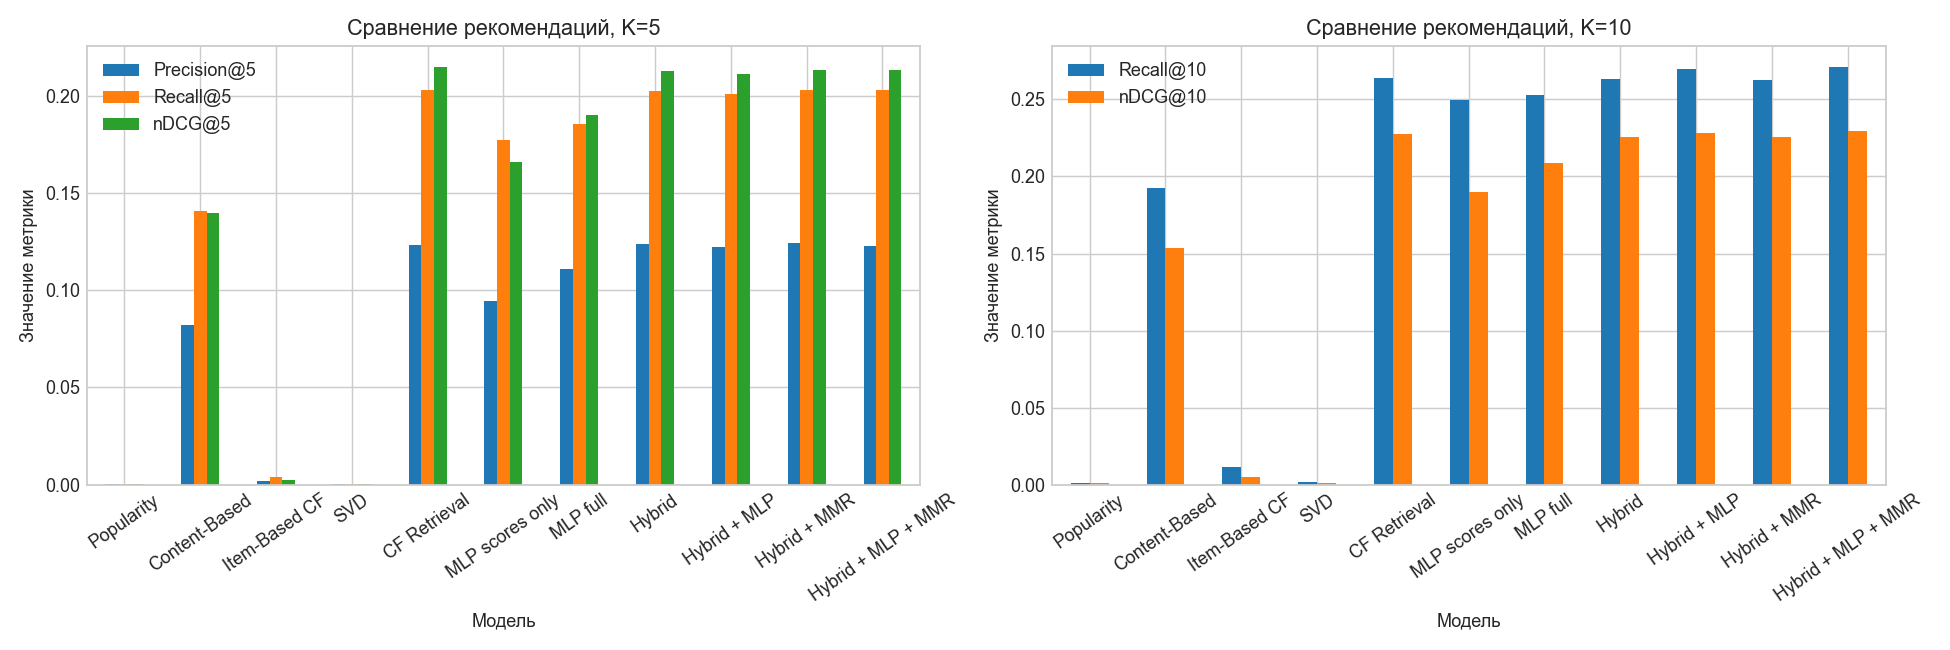

In [5]:
display(tables["model_comparison"].round(4))
print(f"В среднем кандидатов: {tables['model_comparison'].candidate_count.iloc[0]:.1f}")
print(f"Средняя полнота пула: {report['candidate_recall']:.2%}")
figures = make_figures(tables, ROOT)
display(Image(filename=str(ROOT / "figures" / "01_model_comparison.png")))

### Обучение и вклад расширенных признаков

Сравню MLP только на базовых оценках и на всех признаках. Это проверка полезности признаков в одной и той же схеме обучения. Отдельно посмотрю кривые потерь и validation nDCG.

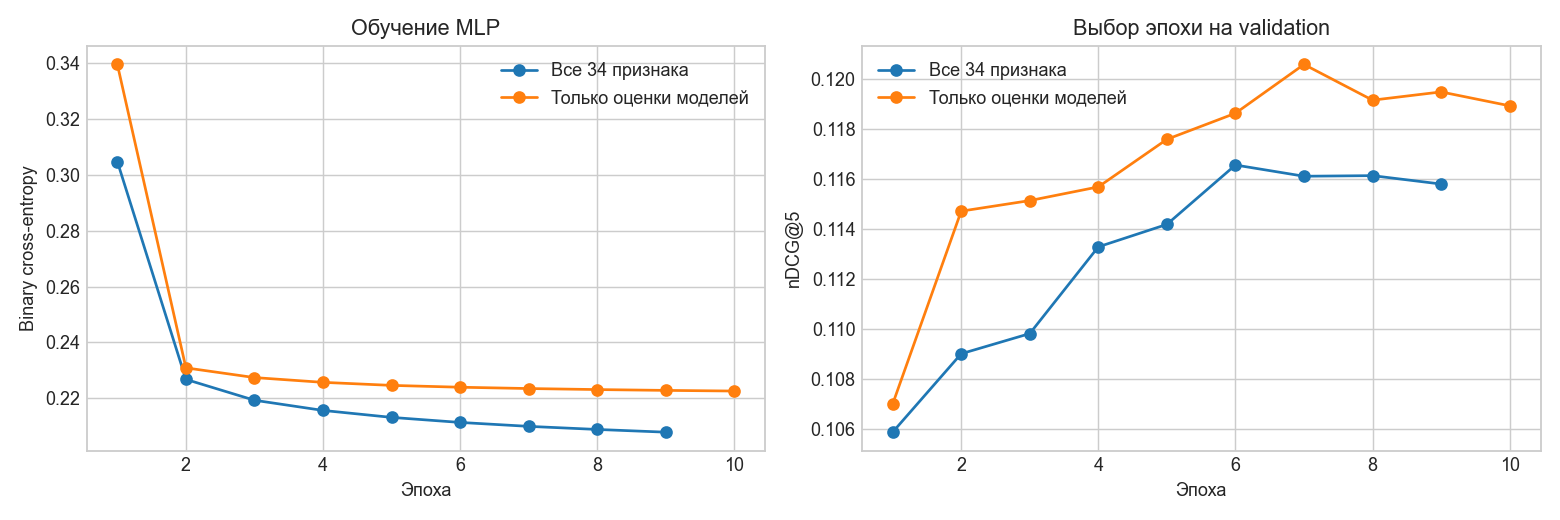

,Precision@5,Recall@10,nDCG@5
model,,,
MLP scores only,0.0944,0.2496,0.1662
MLP full,0.1111,0.2531,0.1905


Разность test nDCG@5 full − scores only: 0.0243
95% bootstrap-интервал: [0.01749 0.03084]


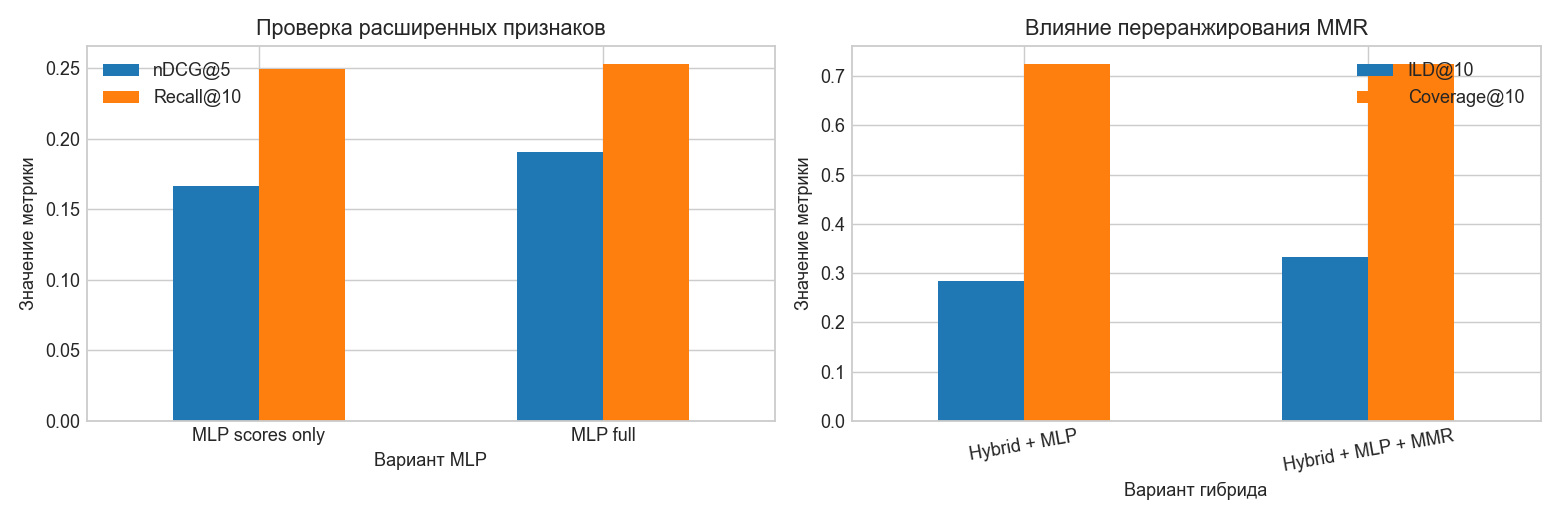

In [6]:
display(Image(filename=str(ROOT / "figures" / "02_neural_learning.png")))
display(tables["model_comparison"].loc[["MLP scores only", "MLP full"], ["Precision@5", "Recall@10", "nDCG@5"]].round(4))
print("Разность test nDCG@5 full − scores only:", round(report["feature_difference"], 5))
print("95% bootstrap-интервал:", np.round(report["feature_CI95"], 5))
display(Image(filename=str(ROOT / "figures" / "06_feature_and_diversity_ablation.png")))

### Релевантность и разнообразие

Настройку разнообразия выбрал до просмотра тестовых результатов. На графике — все проверенные значения λ на validation. Снижение nDCG и рост разнообразия нужно смотреть вместе: разнообразный список сам по себе ещё не означает полезные рекомендации.

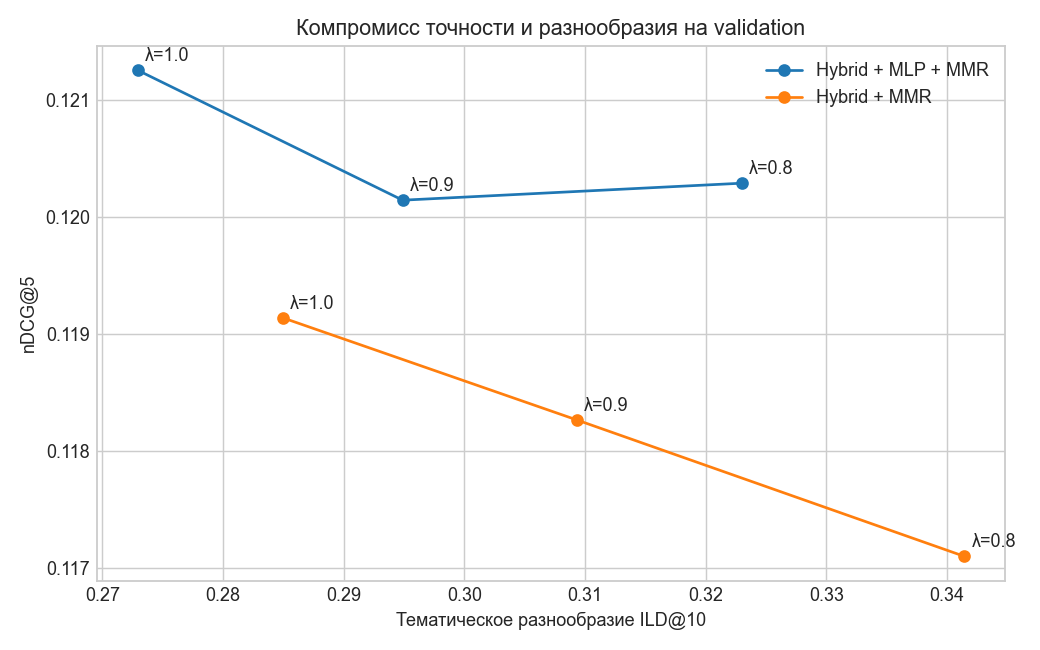

,nDCG@5,Recall@10,ILD@10,Authors@10,Coverage@10
model,,,,,
Hybrid,0.2130,0.2636,0.2870,5.9000,0.7407
Hybrid + MMR,0.2136,0.2624,0.3430,6.1884,0.7422
Hybrid + MLP,0.2116,0.2695,0.2840,5.9528,0.7243
Hybrid + MLP + MMR,0.2134,0.2712,0.3318,6.2140,0.7252


In [7]:
display(Image(filename=str(ROOT / "figures" / "03_diversity_tradeoff.png")))
display(tables["model_comparison"].loc[["Hybrid", "Hybrid + MMR", "Hybrid + MLP", "Hybrid + MLP + MMR"],
    ["nDCG@5", "Recall@10", "ILD@10", "Authors@10", "Coverage@10"]].round(4))

## 6. Сегменты и холодный старт

Разделю тестовых пользователей на группы с 1–4, 5–14 и 15+ обучающими оценками. Размеры групп различаются, поэтому покажу и число пользователей.

Для новых пользователей и книг использую отдельные части, целиком отложенные до обучения. Новым пользователям без опроса остаётся только неперсонализированная выдача. В сценарии новых книг кандидаты выбираются из всего каталога, а релевантными считаются только отложенные новые книги. Эти числа нельзя напрямую сравнивать с основной таблицей.

users   nDCG5  Precision5  Recall5   ILD10
segment model                                                         
1–4     CF Retrieval          186  0.1787      0.0462   0.2312  0.3493
        Content-Based         186  0.1290      0.0398   0.1989  0.2483
        Hybrid                186  0.1617      0.0419   0.2097  0.2570
        Hybrid + MLP          186  0.1695      0.0441   0.2204  0.2680
        Hybrid + MLP + MMR    186  0.1694      0.0430   0.2151  0.3111
        Hybrid + MMR          186  0.1602      0.0419   0.2097  0.3074
        Item-Based CF         186  0.0048      0.0022   0.0108  0.4294
        MLP full              186  0.1671      0.0398   0.1989  0.2670
        MLP scores only       186  0.1788      0.0484   0.2419  0.2970
        Popularity            186  0.0000      0.0000   0.0000  0.4375
        SVD                   186  0.0000      0.0000   0.0000  0.4565
5–14    CF Retrieval         1031  0.1932      0.0638   0.2299  0.3288
        Content-Based        1031  0.1308      0.0446   0.1623  0.2407
        Hybrid               1031  0.1917      0.0638   0.2310  0.3006
        Hybrid + MLP         1031  0.1894      0.0642   0.2294  0.2875
        Hybrid + MLP + MMR   1031  0.1905      0.0646   0.2313  0.3415
        Hybrid + MMR         1031  0.1919      0.0646   0.2312  0.3633
        Item-Based CF        1031  0.0023      0.0012   0.0047  0.4567
        MLP full             1031  0.1738      0.0609   0.2160  0.2801
        MLP scores only      1031  0.1665      0.0580   0.2129  0.2901
        Popularity           1031  0.0004      0.0002   0.0005  0.4375
        SVD                  1031  0.0010      0.0002   0.0010  0.4557
15+     CF Retrieval         1283  0.2380      0.1824   0.1774  0.3027
        Content-Based        1283  0.1489      0.1182   0.1156  0.2217
        Hybrid               1283  0.2375      0.1839   0.1788  0.2804
        Hybrid + MLP         1283  0.2355      0.1800   0.1757  0.2835
        Hybrid + MLP + MMR   1283  0.2381      0.1816   0.1787  0.3270
        Hybrid + MMR         1283  0.2388      0.1846   0.1798  0.3318
        Item-Based CF        1283  0.0020      0.0019   0.0021  0.5208
        MLP full             1283  0.2073      0.1618   0.1594  0.2811
        MLP scores only      1283  0.1642      0.1303   0.1391  0.2612
        Popularity           1283  0.0005      0.0003   0.0004  0.4369
        SVD                  1283  0.0001      0.0002   0.0000  0.4488

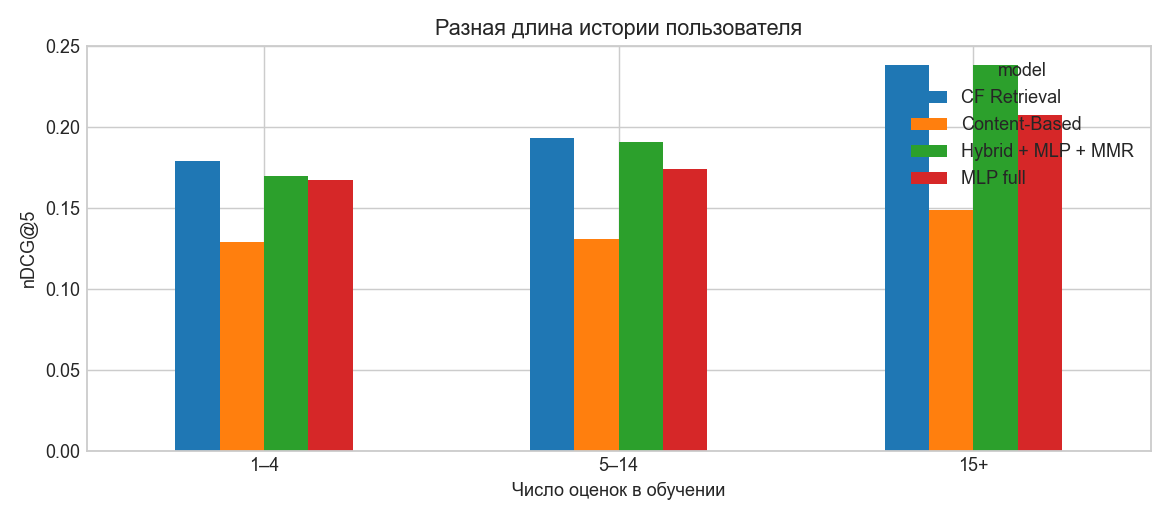

Precision@5  Recall@10  nDCG@5  CandidateRecall  \
scenario  model                                                                 
new_users Popularity               0.0020     0.0009  0.0023           0.0091   
          Content-Based            0.0020     0.0009  0.0023           0.0091   
          Item-Based CF            0.0020     0.0009  0.0023           0.0091   
          SVD                      0.0020     0.0009  0.0023           0.0091   
          CF Retrieval             0.0020     0.0009  0.0023           0.0091   
          MLP scores only          0.0020     0.0009  0.0023           0.0091   
          MLP full                 0.0020     0.0009  0.0023           0.0091   
          Hybrid                   0.0020     0.0009  0.0023           0.0091   
          Hybrid + MLP             0.0020     0.0009  0.0023           0.0091   
          Hybrid + MMR             0.0020     0.0009  0.0023           0.0091   
          Hybrid + MLP + MMR       0.0020     0.0009  0.0023           0.0091   
new_books Popularity               0.0000     0.0000  0.0000           0.4219   
          Content-Based            0.0372     0.2108  0.1080           0.4219   
          Item-Based CF            0.0000     0.0000  0.0000           0.4219   
          SVD                      0.0000     0.0000  0.0000           0.4219   
          CF Retrieval             0.0000     0.0000  0.0000           0.4219   
          MLP scores only          0.0004     0.0110  0.0011           0.4219   
          MLP full                 0.0000     0.0000  0.0000           0.4219   
          Hybrid                   0.0742     0.3686  0.2459           0.4219   
          Hybrid + MLP             0.0610     0.3338  0.1889           0.4219   
          Hybrid + MMR             0.0750     0.3714  0.2479           0.4219   
          Hybrid + MLP + MMR       0.0626     0.3377  0.1931           0.4219   

                              users  
scenario  model                      
new_users Popularity            299  
          Content-Based         299  
          Item-Based CF         299  
          SVD                   299  
          CF Retrieval          299  
          MLP scores only       299  
          MLP full              299  
          Hybrid                299  
          Hybrid + MLP          299  
          Hybrid + MMR          299  
          Hybrid + MLP + MMR    299  
new_books Popularity           1000  
          Content-Based        1000  
          Item-Based CF        1000  
          SVD                  1000  
          CF Retrieval         1000  
          MLP scores only      1000  
          MLP full             1000  
          Hybrid               1000  
          Hybrid + MLP         1000  
          Hybrid + MMR         1000  
          Hybrid + MLP + MMR   1000

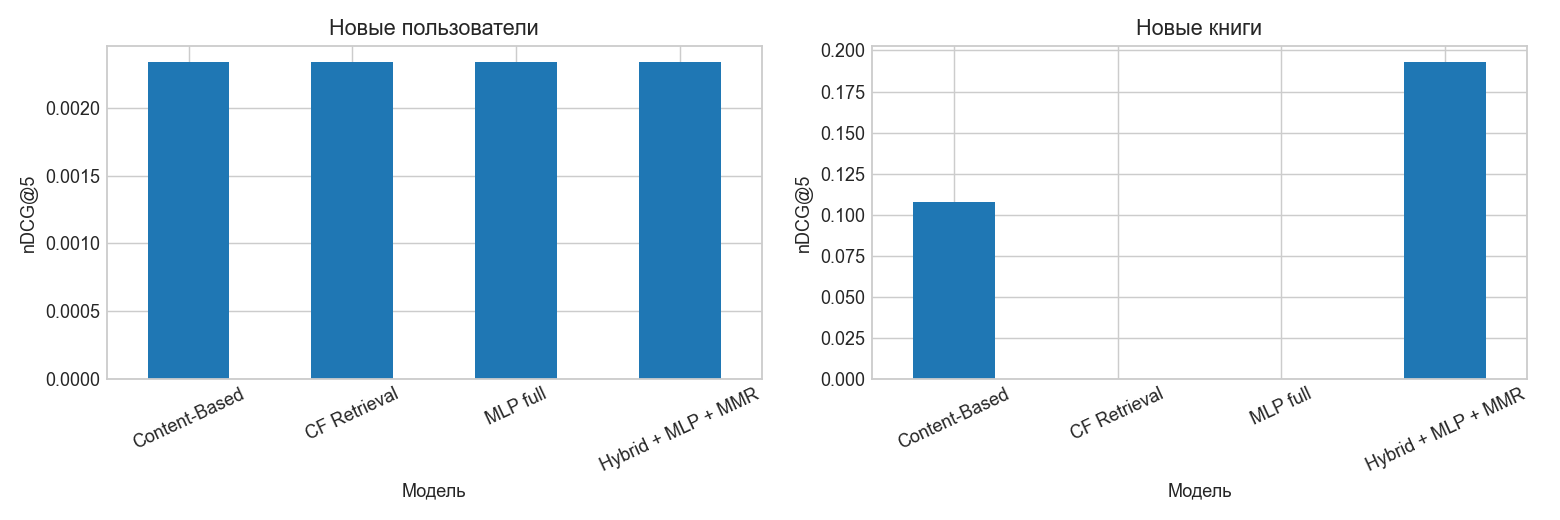

In [8]:
display(tables["history_segments"].round(4))
display(Image(filename=str(ROOT / "figures" / "04_user_segments.png")))
display(tables["cold_start"][["Precision@5", "Recall@10", "nDCG@5", "CandidateRecall", "users"]].round(4))
display(Image(filename=str(ROOT / "figures" / "05_cold_start.png")))

## 7. Проверка функций и пример выдачи

В процессе проверяются непересечение частей данных, формулы метрик на ручном примере, отсутствие прочитанного и совпадение выдачи функций с оценкой. Дополнительный `audit.py` сравнивает классические top-10 в пуле с ранжированием всего каталога, проверяет архитектуру MLP, падение ошибки обучения и ограничение разнообразия на validation.

Ниже пример рекомендаций. `N` может быть от 1 до 10, `user_id` — исходный ID пользователя. По умолчанию функция допускает новые книги. Для основного сравнения использовалось `allow_new_books=False`.

In [9]:
display(bundle.recommend(314, N=5, allow_new_books=False))
print("Совсем новый пользователь:")
display(bundle.recommend(999999, N=5))
print("Проверки пайплайна:", report["checks"])
import audit
audit.main()

,id,clean_title,authors
0,1,The Hunger Games,Suzanne Collins
1,106,Bossypants,Tina Fey
2,74,Looking for Alaska,John Green
3,188,A Dance with Dragons,George R.R. Martin
4,143,All the Light We Cannot See,Anthony Doerr


Совсем новый пользователь:


,id,clean_title,authors
0,9566,Attack of the Deranged Mutant Killer Monster S...,Bill Watterson
1,5207,The Days Are Just Packed: A Calvin and Hobbes ...,Bill Watterson
2,7947,ESV Study Bible,"Anonymous, Lane T. Dennis, Wayne A. Grudem"
3,6361,There's Treasure Everywhere: A Calvin and Hobb...,Bill Watterson
4,5580,The Calvin and Hobbes Lazy Sunday Book,Bill Watterson


Проверки пайплайна: {'split_disjoint': True, 'metric_examples': True, 'no_seen_items': True, 'public_api_matches_evaluation': True, 'cold_holdouts': True, 'unknown_user_fallback': True}


Независимые проверки: {'full_catalog_baselines_match_pool': True, 'mmr_identity': True, 'same_test_users': True, 'candidate_recall_bound': True, 'neural_loss_decreased': True, 'mlp_architecture': True, 'new_user_fallback': True, 'diversity_validation_constraint': True}


## 8. Выводы

Для итогового гибрида также посчитана парная разность nDCG@5 с лучшей одиночной моделью **по validation**. Соперник выбран до теста. Bootstrap — 2000 повторов по тем же пользователям. Это интервал для одной обученной системы и одного разбиения, а не гарантия эффекта при повторном обучении.

In [10]:
print("Соперник по validation:", report["comparison_model"])
print("Разность nDCG@5:", round(report["hybrid_difference"], 5))
print("95% bootstrap-интервал:", np.round(report["hybrid_CI95"], 5))
text = write_documents(tables, report, ROOT)
display(Markdown(text))

Соперник по validation: MLP full
Разность nDCG@5: 0.02286
95% bootstrap-интервал: [0.01783 0.02802]


### Что получилось

1. По nDCG@5 лучше всего оказался **CF Retrieval**: **0.2151**. Классический гибрид получил 0.2130, итоговый гибрид с MLP и MMR — 0.2134. Самая сложная система не обязательно выигрывает по каждой метрике.
2. Вариант **Hybrid + MLP + MMR** лучше по Recall@10: **0.2712**. У итогового гибрида Precision@5 = 0.1230, nDCG@10 = 0.2296. Поэтому выбор зависит от того, насколько важны первые позиции или более полный список.
3. Расширенные признаки помогли MLP на test: nDCG@5 вырос с **0.1662** до **0.1905**. Парная разность — 0.02430, 95% bootstrap-интервал [0.01749; 0.03084]: интервал не включает ноль. Но на validation контрольный MLP был лучше. После переобучения базовых моделей признаки изменились, поэтому этот эффект стоит проверить на других разбиениях.
4. MMR увеличил тематическое разнообразие итоговой выдачи на **16.8%**: ILD@10 изменился с 0.2840 до 0.3318. На validation разрешалось потерять не больше 2% nDCG@5; это ограничение не гарантирует такую же границу на новых данных.
5. В среднем пул содержит 280 книг и **55.9%** релевантных тестовых книг пользователя. Оставшуюся часть ранжировщик вернуть не может. Увеличение полноты кандидатов — отдельное направление улучшения.
6. Для полностью новых пользователей все модели используют Popularity: ни одна модель не знает их вкусы. Для новых книг помогает контентная ветка. По отдельной таблице видно, что MLP без этой ветки практически не находит новые книги.
7. Item-CF для прогноза рейтинга и CF Retrieval решают разные задачи. Первый усредняет отклонения оценок, второй суммирует положительные связи по тем же соседям. Для top-N второй вариант оказался заметно полезнее. SVD, обученный на ошибке рейтинга, тоже не обязан хорошо ранжировать весь каталог.

### Ограничения и идеи

Дат оценок нет, а локальный файл ограничен примерно 100 оценками на книгу. Поэтому реальная популярность и будущая активность здесь отражены не полностью. Теги считаются доступными заранее, хотя исторических снимков нет.

Для обучения MLP я беру до десяти книг без положительной отложенной оценки на одну положительную. Это условные отрицательные примеры, а не доказательство, что книги пользователю не понравились. Полученную вероятность нельзя считать настоящей вероятностью интереса. Из 3500 выбранных пользователей у 1137 не нашлось положительной книги в пуле, поэтому они не дали обучающих строк MLP.

Выбор параметров сделан на 600 validation-пользователях, тест — на 2500. Bootstrap учитывает разброс по этим пользователям, но не разные разбиения и повторное обучение. Разбиение повторяет ДЗ1 для сопоставимости: общие свойства этого теста уже были известны по первой работе.

В дальнейшем можно попробвать OOF-признаки для ранжировщика на нескольких фолдах, более сильную генерацию кандидатов и подбор весов отдельно по сегментам. Для контента — аннотации и Sentence-BERT. Затем нужны временное разбиение и проверка на реальных пользователях.


### Сильные и слабые стороны

| Подход | Что получилось полезным | Ограничения |
|---|---|---|
| Popularity | Простая стартовая выдача без истории | Нет персонализации, новые книги не проходят порог |
| TF-IDF | Находит книги с общими темами и авторами | Зависит от тегов и склонен повторять знакомые темы |
| Item-CF | Прогноз можно объяснить оценёнными соседями | При малом пересечении истории ненадёжны |
| CF Retrieval | Хорошо использует положительные связи между книгами | Новые книги не имеют таких связей |
| SVD | Сжимает историю в факторы и предсказывает рейтинг | Ошибка рейтинга и top-N — разные цели |
| MLP | Использует несколько источников и дополнительные признаки | Зависит от состава кандидатов и распределения обучающих признаков |
| Гибрид с MMR | Позволяет контролировать смешивание и разнообразие | Параметры требуют validation; итог сложнее объяснить |

Я бы не использовал одну модель для всех ситуаций. Для активных пользователей стоит сравнить CF Retrieval и гибрид по нужной метрике, для новых книг оставить контентную ветку, а новым пользователям предложить небольшой опрос. Нейросеть дала полезный дополнительный сигнал, но её преимущество нельзя считать универсальным.

## Источники и файлы

- Код и параметры: `recommender.py`, `run_pipeline.py`, `reporting.py`, `config.json`.
- [MLPClassifier и incremental learning](https://scikit-learn.org/1.7/modules/generated/sklearn.neural_network.MLPClassifier.html).
- [StandardScaler](https://scikit-learn.org/1.7/modules/generated/sklearn.preprocessing.StandardScaler.html).
- [SVD в Surprise](https://surprise.readthedocs.io/en/stable/matrix_factorization.html).
- Данные Goodbooks-10k и классические модели перенесены из первого ДЗ; зависимостей от файлов за пределами этой папки нет.